In [3]:
!pip install openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 250.9/250.9 kB 895.0 kB/s eta 0:00:0036m0:00:010:00:0101


In [4]:
# not to be performed in practical. just for the sake of creation of three files
import pandas as pd

mock_data = {
    'Date' : ['2026-01-01', '2023-01-02', '2023-01-02'],
    'Product' : ['Laptop', 'Mouse', 'Mouse'],
    'Price' : [1000, 20, 20],
    'Quantity' : [1, 5, 5]
}

pd.DataFrame(mock_data).to_csv('sales.csv',index=False)
pd.DataFrame(mock_data).to_excel('sales.xlsx',index=False)
pd.DataFrame(mock_data).to_json('sales.json',orient='records')

missing values per column :  Date        0
Product     0
Price       0
Quantity    0
dtype: int64
Descriptive Statistics :              Price  Quantity  Total_sales
count     4.000000  4.000000     4.000000
mean    510.000000  3.000000   550.000000
std     565.803264  2.309401   519.615242
min      20.000000  1.000000   100.000000
25%      20.000000  1.000000   100.000000
50%     510.000000  3.000000   550.000000
75%    1000.000000  5.000000  1000.000000
max    1000.000000  5.000000  1000.000000
sales Aggregated product :    Product  Total_sales
0  Laptop         2000
1   Mouse          200


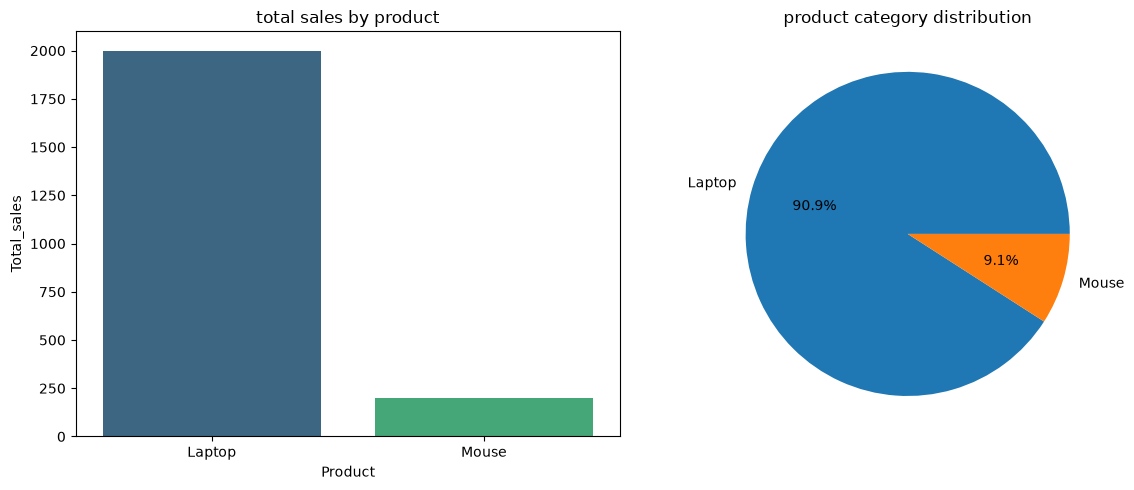

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_csv = pd.read_csv('sales.csv')
df_excel = pd.read_excel('sales.xlsx')
df_json = pd.read_json('sales.json')

df_unified = pd.concat([df_csv, df_excel, df_json], ignore_index=True)

print("missing values per column : ", df_unified.isnull().sum())

df_clean = df_unified.dropna().drop_duplicates()

df_clean['Total_sales'] = df_clean['Price'] * df_clean['Quantity']

df_clean[['Year','Month','Day']] = df_clean['Date'].str.split('-',expand=True)

print('Descriptive Statistics :', df_clean.describe())

category_sales = df_clean.groupby('Product')['Total_sales'].sum().reset_index()
print("sales Aggregated product : ", category_sales)

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
sns.barplot(x='Product', y='Total_sales', data = category_sales, hue='Product', palette='viridis')
plt.title('total sales by product')

plt.subplot(1,2,2)
plt.pie(category_sales['Total_sales'], labels=category_sales['Product'], autopct = '%1.1f%%')
plt.title('product category distribution')

plt.tight_layout()
plt.show()